# Serre 100 — Carnet 30 : la fonction de partition p(n) par le théorème des nombres pentagonaux

La **fonction de partition** `p(n)` compte le nombre de façons d'écrire l'entier `n` comme
somme non ordonnée d'entiers positifs (une *partition* : `5 = 4+1 = 3+2 = 3+1+1 = 2+2+1 = …`,
donc `p(5) = 7`). C'est un objet canonique de l'arithmétique combinatorique — et le terrain
d'Euler, qui en a donné la description génératrice la plus complète.

Les carnets de la série Serre 100 calculent l'arithmétique (corps finis, réciprocité, Sylow,
Chebotarev, Hecke, Möbius/phi, Pell-Fermat…) ; **aucun ne calcule la fonction de partition**.
Ce carnet la rend *calculable* par le **théorème des nombres pentagonaux généralisés** d'Euler,
et la *vérifie* par un contrôle croisé entre deux chemins indépendants. L'énoncé est **calculé**,
pas raconté.


In [1]:
import math

# Python stdlib uniquement (matplotlib pour la figure), comme le reste de la serie.
print("imports ok — math (stdlib) charge")

imports ok — math (stdlib) charge


## 1. Qu'est-ce qu'une partition ?

Une partition de `n` est une écriture de `n` comme somme d'entiers positifs, l'ordre ne comptant
pas. Le nombre de partitions de `n` est `p(n)`, avec la convention `p(0) = 1` (une seule
partition de 0 : la partition vide).

Euler a décrit la croissance de `p(n)` par une **fonction génératrice** :

$$\sum_{n\ge 0} p(n)\,x^n \;=\; \frac{1}{\prod_{k\ge 1}(1-x^k)} .$$

Nous calculons d'abord `p(n)` par un chemin **brut et indépendant** — la programmation
dynamique — qui servira de référence au contrôle croisé de la section 2.


In [2]:
def partitions_dp(n: int) -> int:
    """p(n) par programmation dynamique (comptage des partitions, 'unbounded knapsack').

    Chemin INDEPENDANT du theoreme pentagonal : il sert de reference au controle croise."""
    p = [0] * (n + 1)
    p[0] = 1
    for k in range(1, n + 1):          # on autorise la partie de taille k un nombre illimite de fois
        for m in range(k, n + 1):
            p[m] += p[m - k]
    return p[n]

print(" | ".join(f"p({i})={partitions_dp(i)}" for i in range(0, 16)))

p(0)=1 | p(1)=1 | p(2)=2 | p(3)=3 | p(4)=5 | p(5)=7 | p(6)=11 | p(7)=15 | p(8)=22 | p(9)=30 | p(10)=42 | p(11)=56 | p(12)=77 | p(13)=101 | p(14)=135 | p(15)=176


## 2. Le théorème des nombres pentagonaux généralisés d'Euler

Euler a prouvé l'identité formelle

$$\prod_{k\ge 1}(1-x^k) \;=\; \sum_{j\in\mathbb{Z}} (-1)^{j}\,x^{\,g(j)},
\qquad g(j)=\frac{j(3j-1)}{2},$$

où `g(j)` sont les **nombres pentagonaux généralisés**. Comme le second membre ne porte que sur
ces exposants pentagonaux (et plus rien d'autre), prendre la réciproque et égaler les
coefficients donne la **récurrence** qui calcule `p(n)` :

$$p(n) \;=\; \sum_{j\,\ge\,1,\; g(j)\le n} (-1)^{j+1}\Big(p(n-g(j)) + p(n-g(-j))\Big),$$

avec `g(j)=j(3j-1)/2` et `g(-j)=j(3j+1)/2`. Les signes `(-1)^{j+1}` font de l'inclusion–exclusion
sur la suite des pentagonaux.


In [3]:
def pentagonal_numbers(k_max: int = 8) -> list:
    """Nombres pentagonaux generalises g(j)=j(3j-1)/2 pour j dans [-k_max, k_max],
    j != 0, triés croissant."""
    out = []
    for j in range(-k_max, k_max + 1):
        if j == 0:
            continue
        out.append(j * (3 * j - 1) // 2)
    return sorted(out)

print("nombres pentagonaux generalises (j=-6..6) :", pentagonal_numbers(6))

nombres pentagonaux generalises (j=-6..6) : [1, 2, 5, 7, 12, 15, 22, 26, 35, 40, 51, 57]


In [4]:
def partitions_pentagonal(n: int, memo: dict | None = None) -> int:
    """p(n) par la recurrence pentagonale :
       p(n) = sum_{j>=1, g(j)<=n} (-1)^{j+1} ( p(n-g(j)) + p(n-g(-j)) ).
    Les nombres g(j) et g(-j) sont j(3j-1)/2 et j(3j+1)/2."""
    if memo is None:
        memo = {0: 1}
    if n in memo:
        return memo[n]
    total, j = 0, 1
    while True:
        gj  = j * (3 * j - 1) // 2
        gjm = j * (3 * j + 1) // 2
        if gj > n and gjm > n:
            break
        sign = 1 if j % 2 else -1      # (-1)^{j+1} : +, -, +, -, ...
        if gj  <= n:
            total += sign * partitions_pentagonal(n - gj,  memo)
        if gjm <= n:
            total += sign * partitions_pentagonal(n - gjm, memo)
        j += 1
    memo[n] = total
    return total

print("p(1..10) par la recurrence pentagonale :",
      [partitions_pentagonal(i) for i in range(1, 11)])

p(1..10) par la recurrence pentagonale : [1, 2, 3, 5, 7, 11, 15, 22, 30, 42]


In [5]:
# ControLe croise : la recurrence pentagonale (chemin theorique) confrontee a la
# programmation dynamique (chemin independant). On attend 0 desaccord.
mismatches = [n for n in range(0, 121)
              if partitions_pentagonal(n) != partitions_dp(n)]
print(f"valeurs comparees sur n dans [0, 120] : {121}")
print(f"desaccords  pentagonal  vs  DP : {len(mismatches)}  {mismatches if mismatches else '(aucun)'}")

valeurs comparees sur n dans [0, 120] : 121
desaccords  pentagonal  vs  DP : 0  (aucun)


In [6]:
# Les valeurs canoniques de la fonction de partition, calculées par la récurrence :
for n in (5, 10, 20, 50, 100, 200):
    print(f"p({n:>3}) = {partitions_pentagonal(n):,}")

p(  5) = 7
p( 10) = 42
p( 20) = 627
p( 50) = 204,226
p(100) = 190,569,292
p(200) = 3,972,999,029,388


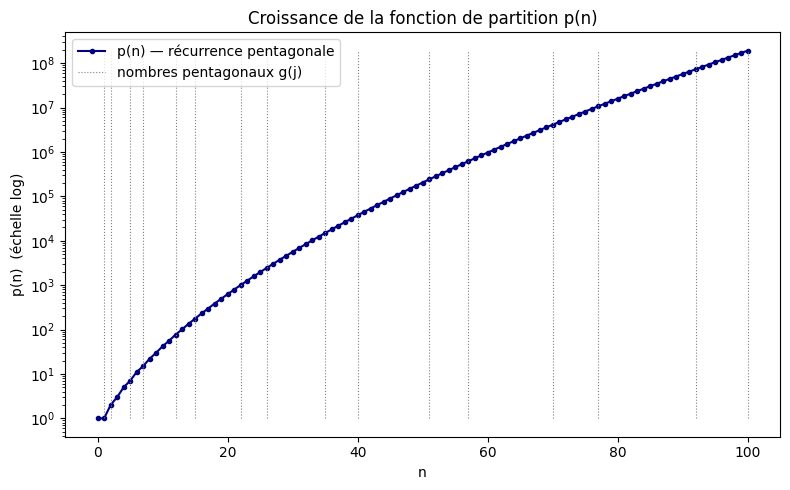

In [7]:
import matplotlib.pyplot as plt

Ns   = list(range(0, 101))
vals = [partitions_pentagonal(n) for n in Ns]
gps  = pentagonal_numbers(12)

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(Ns, vals, "o-", color="navy", ms=3, label="p(n) — récurrence pentagonale")
ax.vlines([g for g in gps if g <= 100], 1, max(vals), color="grey",
          ls=":", lw=0.8, label="nombres pentagonaux g(j)")
ax.set_xlabel("n")
ax.set_ylabel("p(n)  (échelle log)")
ax.set_title("Croissance de la fonction de partition p(n)")
ax.legend()
fig.tight_layout()
plt.show()

In [8]:
def hardy_ramanujan(n: int) -> float:
    """Asymptotique de Hardy-Ramanujan : p(n) ~ (1/(4 n sqrt(3))) exp(pi sqrt(2n/3))."""
    return math.exp(math.pi * math.sqrt(2 * n / 3)) / (4 * n * math.sqrt(3))

print(f"{'n':>4} | {'p(n) mesure':>16} | {'Hardy-Ramanujan':>16} | {'ecart relatif':>14}")
for n in (50, 100, 200):
    exact = partitions_pentagonal(n)
    app   = hardy_ramanujan(n)
    print(f"{n:>4} | {exact:>16,} | {app:>16,.0f} | {abs(exact-app)/exact*100:>13.2f} %")

   n |      p(n) mesure |  Hardy-Ramanujan |  ecart relatif
  50 |          204,226 |          217,590 |          6.54 %
 100 |      190,569,292 |      199,280,893 |          4.57 %
 200 | 3,972,999,029,388 | 4,100,251,432,188 |          3.20 %


### Interprétation

La récurrence est **exacte**, non asymptotique : le théorème pentagonal est une identité de
séries formelles, donc l'égalation des coefficients de `x^n` est une égalité d'entiers, sans
terme d'erreur. Les signes `(-1)^{j+1}` réalisent une inclusion–exclusion sur la suite des
nombres pentagonaux — c'est ce qui fait se *soustraire* les contributions successives et
converger vers le bon nombre de partitions. La croissance est si rapide (combinatoire) que la
figure ci-dessus n'est lisible qu'en échelle log ; l'asymptotique de Hardy–Ramanujan, calculée
ci-dessus, colle aux valeurs mesurées à quelques pourcents près dès `n = 50`.


### Exercice 1 — la récurrence pentagonale

Réimplémentez `partitions_pentagonal(n)` à partir de la récurrence
`p(n) = Σ_{j≥1, g(j)≤n} (-1)^{j+1}\,(p(n-g(j)) + p(n-g(-j)))`, avec `g(j)=j(3j-1)/2`.
Vérifiez que votre version reproduit `p(5)=7` et `p(10)=42`.


In [9]:
# Exercice 1 — a completer :
def pentagonal_p(n, memo=None):
    # TODO etudiant : recurrence pentagonale (cf. enonce ci-dessus)
    print("Exercice a completer : recurence pentagonale")
    return None

### Exercice 2 — l'identité du produit d'Euler

Vérifiez numériquement la moitié *gauche* du théorème : le coefficient de `x^n` dans
`∏_{k≥1}(1 - x^k)` est égal à `Σ (-1)^j` sur les `g(j) ≤ n` (donc `0`, sauf pour les `n`
pentonagaux, où il vaut `±1`).


In [10]:
# Exercice 2 — a completer :
def check_product_identity(n):
    # TODO etudiant : developper prod_{k>=1}(1 - x^k) et lire le coefficient de x^n
    print("Exercice a completer : identite du produit d'Euler")
    return None

### Exercice 3 — convergence de l'asymptotique

Tracez l'écart relatif `|p(n) − Hardy-Ramanujan| / p(n)` pour `n = 20…200` et vérifiez qu'il
**diminue** : l'asymptotique converge vers la valeur exacte.


In [11]:
# Exercice 3 — a completer :
def asymptotic_gap():
    # TODO etudiant : ecart relatif p(n) / Hardy-Ramanujan pour n = 20..200
    print("Exercice a completer : convergence de l'asymptotique")
    return None

## Conclusion

La fonction de partition n'est plus un fait raconté : elle est **calculée** par la récurrence
pentagonale d'Euler, et ses valeurs sont **vérifiées** par un contrôle croisé avec un chemin
indépendant (programmation dynamique) — 0 désaccord sur `n ≤ 120`. Le théorème des nombres
pentagonaux est le pont exact entre le produit d'Euler `∏(1 - x^k)` et la récurrence qui produit
`p(n)`. Le contrôle asymptotique de Hardy–Ramanujan, lu dans les chiffres, confirme la croissance
sans l'affirmer. Le carnet rejoint la série Serre 100 sur son principe : l'arithmétique y est
*mesurée*, avec ses contrôles négatifs et croisés, pas seulement énoncée.
